#Antecedentes

In [1]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 20.4 MB/s eta 0:00:00


In [2]:
import pandas as pd
#---------------------- RDKit packages
from rdkit.Chem import AllChem
from rdkit.Chem import rdMolDescriptors
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem import Draw
from rdkit.Chem import PandasTools
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG#generacion de la imagen con farmacoforo resaltado

#definimos variables

In [3]:
! gdown --id 1RtoyG9CiOHtrkERzGBORYDpdp7VIJXvO #Invoca al archivo desde Drive
# df = pd.read_excel("s_au.xlsx")#en formato excel
#conversion de excel a dataframe
dataframe = pd.read_excel("Romina_mordred.xlsx")

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1RtoyG9CiOHtrkERzGBORYDpdp7VIJXvO
To: /content/Romina_mordred.xlsx
100% 1.76M/1.76M [00:00<00:00, 48.2MB/s]


In [4]:

#generamos las molescuals a partir de los smiles
PandasTools.AddMoleculeColumnToFrame(dataframe,'SMILES', 'Structure')
dataframe['pIC50'] = dataframe['pEC50'].round(2) #trabajamos con dos cifras
#dataframe.head()

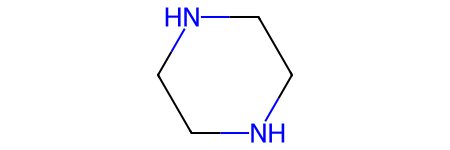

In [5]:
#farmacoforo
m= AllChem.MolFromSmiles("C1NCCNC1")
m

/usr/local/lib/python3.13/dist-packages/rdkit/Chem/Draw/IPythonConsole.py:376: UserWarning: Truncating the list of molecules to be displayed to 50. Change the maxMols value to display more.
  warnings.warn(


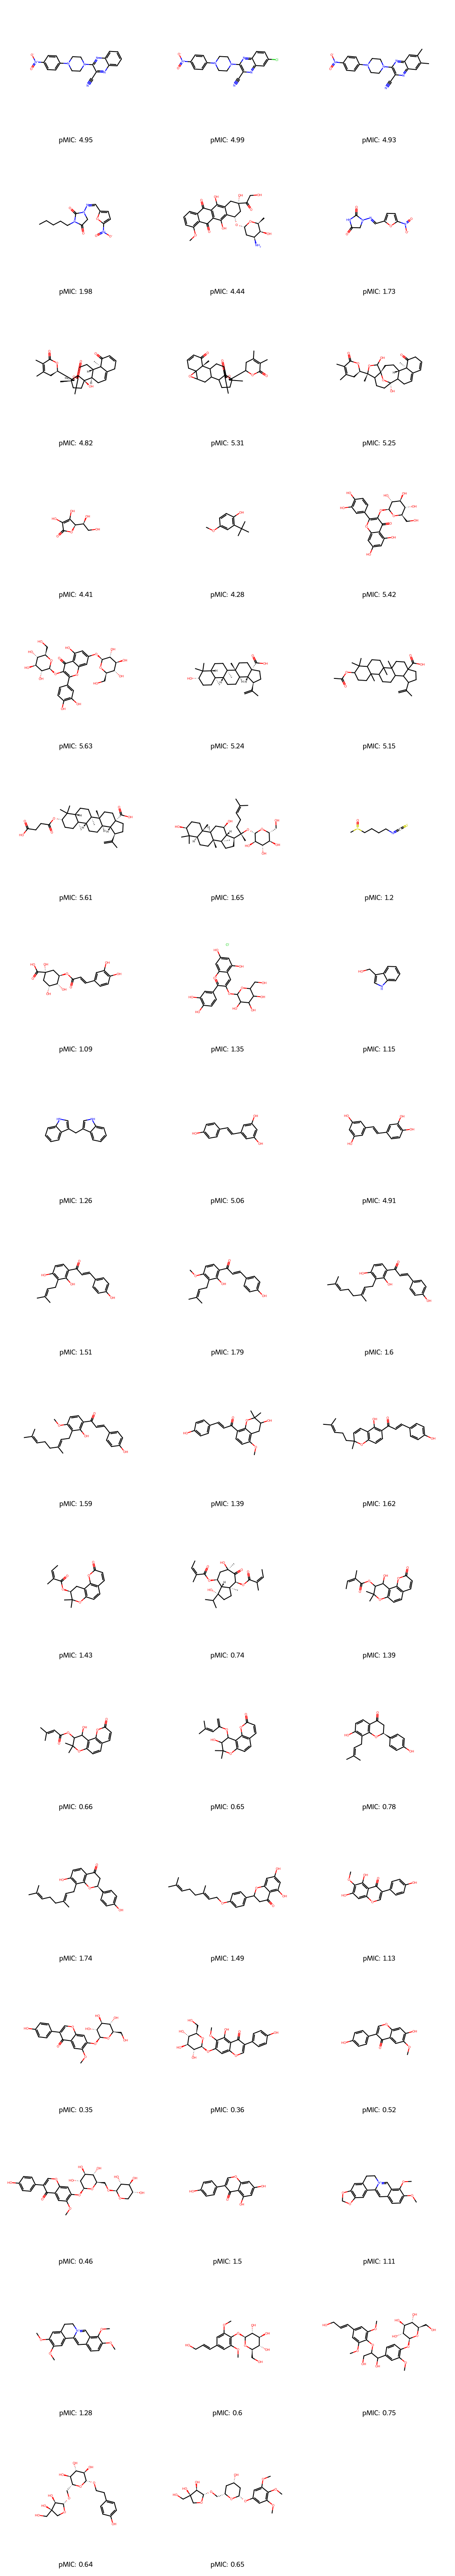

In [6]:
#tablita de dataframe
Draw.MolsToGridImage([x for x in dataframe["Structure"]],#[:20], maxMols=100,
                     legends=['pMIC: '+ str(x) for x in dataframe.pIC50],
                     subImgSize=(350,350), molsPerRow=3)

#Busqueda de subestructura

In [7]:
#Revisa si una molecula contiene la substructura 'm'
# e indica el numero de coincidencias True y falsos
def find_m_structure(mol):
    return mol.HasSubstructMatch(m)
dataframe['Has_M_Structure'] = dataframe['Structure'].apply(find_m_structure)
print(dataframe['Has_M_Structure'].value_counts())

Has_M_Structure
False    100
True       4
Name: count, dtype: int64


In [8]:
#Filtramos las moléculas que si contienen la subestructura m
molecules_with_m = dataframe[dataframe['Has_M_Structure'] == True] #esta variable la usaremos más adelante

In [9]:
#esta función resalta las zonas donde la subestructura m concide con los compuestos
def highlight_substructure(mol, substructure):
    drawer = rdMolDraw2D.MolDraw2DSVG(400, 300)
    drawer.DrawMolecule(mol, highlightAtoms=mol.GetSubstructMatch(substructure))
    drawer.FinishDrawing()
    return drawer.GetDrawingText()

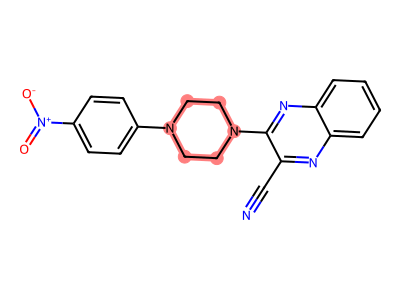

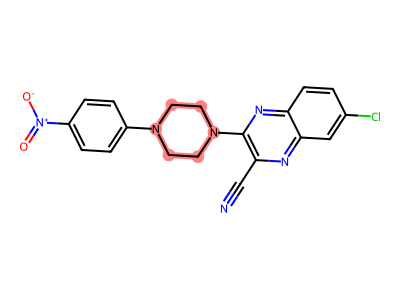

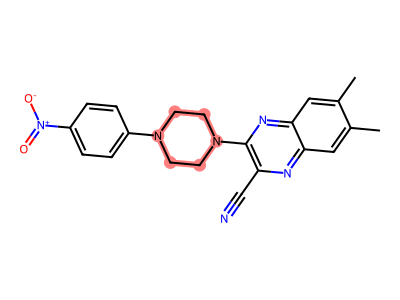

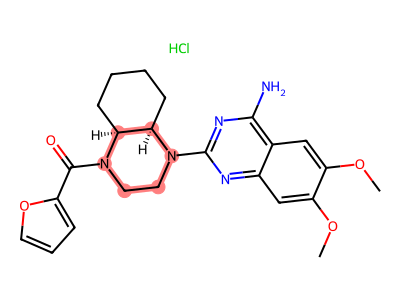

In [10]:
#generacion de la imagen con farmacoforo resaltado
for i in range(min(50, len(molecules_with_m))): #aquí volvemos a usar las moléculas que si contienen la subestructura m
    mol = molecules_with_m["Structure"].iloc[i]
    highlighted_image = highlight_substructure(mol, m)
    display(SVG(highlighted_image))

Realizado por
Dr. Erick Correa
Maricarmen Cedillo:
Cristopher Verde
FES Zaragoza UNAM